# Phase 4 — depth0/experts60, fixed-loss KD (500 steps)

~55% params (experts-only); B300 full-param KD. Best HumanEval uses step-49 checkpoint.


In [1]:
import json
from pathlib import Path

DEBUG = Path("../docs/debug")
PREFIX = "phase4_depth0_experts60_fixedloss_short"
summary = json.loads((DEBUG / f"{PREFIX}_run_summary.json").read_text())
summary

{'build_wall_clock_sec': None,
 'build_wall_clock_human': '0h 0m 0s',
 'zero_shot_loss': 0.9594,
 'build_run': None,
 'kd_wall_clock_sec': 2529,
 'kd_wall_clock_human': '0h 42m 9s',
 'steps': 500,
 'warmup_steps': 75,
 'peak_lr': 0.0001,
 'teacher_cache_hub': 'sartajbhuvaji/bonsai-teacher-logits-baseline',
 'candidate_hub': 'sartajbhuvaji/bonsai-candidate-depth0-experts60',
 'val_best_step': 49,
 'val_best': 0.13568666631666323,
 'val_final_step': 499,
 'val_final': 0.2036684040352702,
 'humaneval_final_pass_at_1': 0.675,
 'humaneval_best_pass_at_1': 0.7,
 'distill_run': 'runs/20261015T192407Z-a0f888-distill-depth0-experts60-vs-baseline-500-warmup75-lr1e4-fixedloss',
 'humaneval_final_run': 'runs/20261015T201216Z-d804ca-distill-depth0-experts60-fixedloss-short-humaneval-ts-n40-final',
 'humaneval_best_run': 'runs/20261015T200608Z-fd8b99-distill-depth0-experts60-fixedloss-short-humaneval-ts-n40-best'}

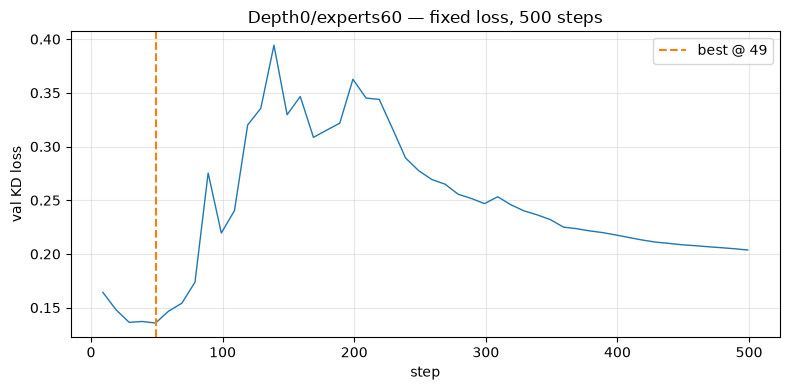

In [2]:
import matplotlib.pyplot as plt

vals = []
for line in (DEBUG / f"{PREFIX}_kd_metrics.jsonl").read_text().splitlines():
    row = json.loads(line)
    if "val_loss" in row:
        vals.append((row["step"], row["val_loss"]))
steps, losses = zip(*vals, strict=True)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(steps, losses, linewidth=1)
ax.axvline(
    summary["val_best_step"], color="C1", linestyle="--", label=f"best @ {summary['val_best_step']}"
)
ax.set_xlabel("step")
ax.set_ylabel("val KD loss")
ax.set_title("Depth0/experts60 — fixed loss, 500 steps")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [3]:
comparison = {
    "zero_shot_loss": 0.9594,
    "params_fraction": 0.555,
    "fixed_loss_short_best_pass_at_1": 0.7,
    "fixed_loss_short_final_pass_at_1": 0.675,
    "depth0_experts97_short_ref": 0.4,
    "depth12_fixed_loss_3k_best": 0.55,
}
comparison

{'zero_shot_loss': 0.9594,
 'params_fraction': 0.555,
 'fixed_loss_short_best_pass_at_1': 0.7,
 'fixed_loss_short_final_pass_at_1': 0.675,
 'depth0_experts97_short_ref': 0.4,
 'depth12_fixed_loss_3k_best': 0.55}

In [4]:
gens = json.loads(
    (
        DEBUG
        / "phase4_depth0_experts60_fixedloss_short_humaneval_generations_best_multiple-ts.json"
    ).read_text()
)
for i in range(3):
    text = gens[i][0]
    print("=" * 72)
    print(f"problem {i} (len={len(text)})")
    print(text[:1200])
    if len(text) > 1200:
        print("... [truncated]")

problem 0 (len=486)
//Check if in given array of numbers, are any two numbers closer to each other than
// given threshold.
// >>> has_close_elements([1.0, 2.0, 3.0], 0.5)
// false
// >>> has_close_elements([1.0, 2.8, 3.0, 4.0, 5.0, 2.0], 0.3)
// true
function has_close_elements(numbers: number[], threshold: number): boolean {
    for (let i = 0; i < numbers.length - 1; i++) {
        if (Math.abs(numbers[i] - numbers[i + 1]) < threshold) {
            return true;
        }
    }
    return false;
}

problem 1 (len=914)
//Input to this function is a string containing multiple groups of nested parentheses. Your goal is to
// separate those group into separate strings and return the array of those.
// Separate groups are balanced (each open brace is properly closed) and not nested within each other
// Ignore any spaces in the input string.
// >>> separate_paren_groups("( ) (( )) (( )( ))")
// ["()", "(())", "(()())"]
function separate_paren_groups(paren_string: string): string[] {
    c